# Supplementary Fig S1 · Datasets and index build cost

The parts of the old Fig 2 (`_backup_2026-11-01/F2_cost.ipynb`) that are not in the main Fig 2 (storage per section is
main Fig 2A).

* **A** the eight indexed sections (seed-0 build): cells, genes, index tiles, niches, blocks.
* **B** build time of Spindle-naive, the seconds each other index adds, and the peak memory of the whole build.
* **C–D** storage, build time and peak memory against the number of cells (tonsil, subsampled) and of genes
  (lymph node 5k).

Mean ± s.d. over seeds 0–4 in B.

**Run first:** `R0_index_cache` → `R1_index_cost` (reads `results/index_cost/builds.csv` and `ladder.csv`).
Writes `figures/figS1_build/panels/{A..D,legend}.{pdf,png}` and `figures/figS1_build/figS1_build.{pdf,png}`.

In [1]:
import math
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
sys.path.insert(0, str(ROOT / "experiments" / "common"))
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

import style as ps

FIG = "figS1_build"
RES = ROOT / "results" / "index_cost"
ORDER = ps.DATASET_ORDER
TC = ps.TIER_COLORS

b = pd.read_csv(RES / "builds.csv")
b["naive_build_s"] = b[["prepare_s", "layout_s", "naive_s"]].sum(axis=1)
b["key"] = pd.Categorical(b["key"], ORDER, ordered=True)
b = b.sort_values(["key", "seed"])
lad = pd.read_csv(RES / "ladder.csv")
print(sorted(set(b.tag)), sorted(set(lad.tag)))

# row 1 geometry (mm): every row-1 panel has the same height and vertical margins, so the dataset rows line up
H1, TOP, BOTTOM = 54.0, 6.5, 11.0
ROW_OFF = 0.17  # the two storage rows of a dataset
STORAGE_XLIM = (0.7, 8000.0)  # MB
W_A, W_C = 82.0, 98.0
# row 2: a title line, then three stacked axes sharing x
W_D, TITLE, H_TOP, H_BOTTOM = 88.0, 5.0, 32.0, 38.0
H2 = TITLE + 2 * H_TOP + H_BOTTOM


def box(fig, x, y, w, h):
    """Axes occupying the w x h mm box at (x, y) mm from the panel's top-left corner."""
    W, H = ps.size_mm(fig)
    return ps.axes(fig, left=x, top=y, right=W - x - w, bottom=H - y - h)


def rows(ax):
    n = len(ORDER)
    ax.set_ylim(n - 0.5, -0.5)
    ax.set_yticks(range(n))
    return n


def mean_sd(col):
    g = b.groupby("key", observed=True)[col]
    return g.mean().to_numpy(), g.std().to_numpy()


def marker(ax, x, y, tier, mk, filled=True, xerr=None, ms=3.2):
    k = TC[tier]
    ax.errorbar(x, y, xerr=xerr, fmt=mk, ms=ms, color=k, mfc=k if filled else "white", mec=k, mew=0.8,
                elinewidth=0.6, zorder=3)


def row_axis(ax):
    ax.set_yticklabels([])
    ax.tick_params(axis="y", length=0)
    ax.spines["left"].set_visible(False)

['method-v2'] ['method-v2']


## A · Datasets (seed-0 build)

figures/figS1_build/panels/A.pdf/.png: 82 x 54 mm, 0.0 / 0.4 MB


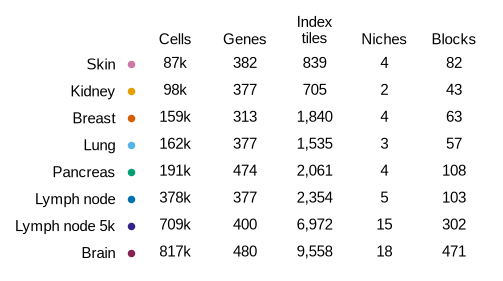

In [2]:
def k_cells(v):
    return f"{v / 1000:.0f}k"


def panel_a(fig):
    s0 = b[b.seed == 0].set_index("key").loc[ORDER]
    cols = [("n_cells", "Cells", k_cells), ("p", "Genes", lambda v: f"{v:.0f}"),
            ("n_train", "Index\ntiles", lambda v: f"{v:,.0f}"), ("n_niches", "Niches", lambda v: f"{v:.0f}"),
            ("n_blocks", "Blocks", lambda v: f"{v:.0f}")]
    ax = box(fig, 22.0, TOP, W_A - 23.0, H1 - TOP - BOTTOM)
    n = rows(ax)
    ax.set_yticklabels([ps.DATASET_LABELS[k] for k in ORDER])
    for j, (col, _, f) in enumerate(cols):
        for i, v in enumerate(s0[col].to_numpy(float)):
            ax.text(j, i, f(v), ha="center", va="center", fontsize=ps.TICK_PT)
    for i, k in enumerate(ORDER):  # the dataset's colour, as in every other figure
        ax.plot(-0.64, i, "o", ms=2.6, color=ps.DATASET_COLORS[k], clip_on=False)
    ax.set_xlim(-0.5, len(cols) - 0.5)
    ax.set_xticks(range(len(cols)))
    ax.set_xticklabels([c for _, c, _ in cols])
    ax.xaxis.tick_top()
    ax.tick_params(axis="both", length=0)
    ax.tick_params(axis="y", pad=12)
    for side in ("left", "bottom", "top"):
        ax.spines[side].set_visible(False)


fig = ps.panel(W_A, H1); panel_a(fig); ps.save_panel(fig, FIG, "A")

## B · Build cost: Spindle-naive's full build (file loading excluded), what each other index adds, peak memory

figures/figS1_build/panels/B.pdf/.png: 98 x 54 mm, 0.0 / 0.3 MB


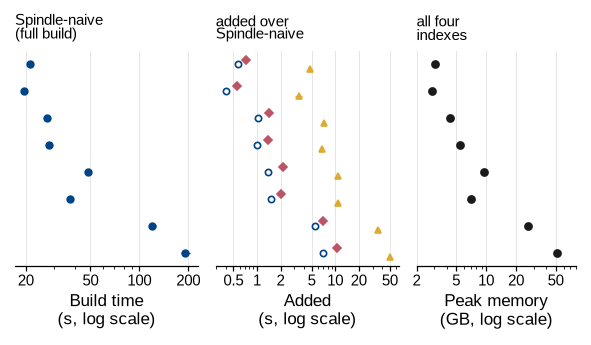

In [3]:
def panel_c(fig):
    y = np.arange(len(ORDER))
    specs = [(0.0, 34.0, "Build time\n(s, log scale)", "Spindle-naive\n(full build)"),
             (34.0, 34.0, "Added\n(s, log scale)", "added over\nSpindle-naive"),
             (68.0, 30.0, "Peak memory\n(GB, log scale)", "all four\nindexes")]
    axs = []
    for x0, w, xlabel, title in specs:
        ax = box(fig, x0 + 1.5, TOP, w - 3.0, H1 - TOP - BOTTOM)
        rows(ax)
        ax.set_xscale("log")
        ps.log_grid(ax, "x")
        ax.set_xlabel(xlabel)
        row_axis(ax)
        fig.text((x0 + 1.5) / W_C, 1 - 0.3 / H1, title, fontsize=ps.TICK_PT, va="top", linespacing=1.0)
        axs.append(ax)
    mu, sd = mean_sd("naive_build_s")
    marker(axs[0], mu, y, "naive", "o", xerr=sd)
    for col, tier, mk, filled, dy in (("spindle_s", "spindle", "D", True, -ROW_OFF),
                                      ("naive_partial_s", "naive", "o", False, 0.0),
                                      ("spindle_partial_s", "spindle_partial", "^", True, ROW_OFF)):
        mu, sd = mean_sd(col)
        marker(axs[1], mu, y + dy, tier, mk, filled, xerr=sd, ms=3.0)
    mu, sd = mean_sd("peak_gb_spindle_partial")
    axs[2].errorbar(mu, y, xerr=sd, fmt="o", ms=3.2, color=ps.INK, elinewidth=0.6, zorder=3)
    axs[2].set_xlim(2, 80)
    for ax in axs:
        ps.plain_log(ax, "x", subs=(1.0, 2.0, 5.0))


fig = ps.panel(W_C, H1); panel_c(fig); ps.save_panel(fig, FIG, "B")

## C–D · Ladders: storage, build time (Spindle-naive's full build, solid; what each other index adds, dashed), peak memory

figures/figS1_build/panels/C.pdf/.png: 88 x 107 mm, 0.0 / 0.7 MB
figures/figS1_build/panels/D.pdf/.png: 88 x 107 mm, 0.0 / 0.6 MB


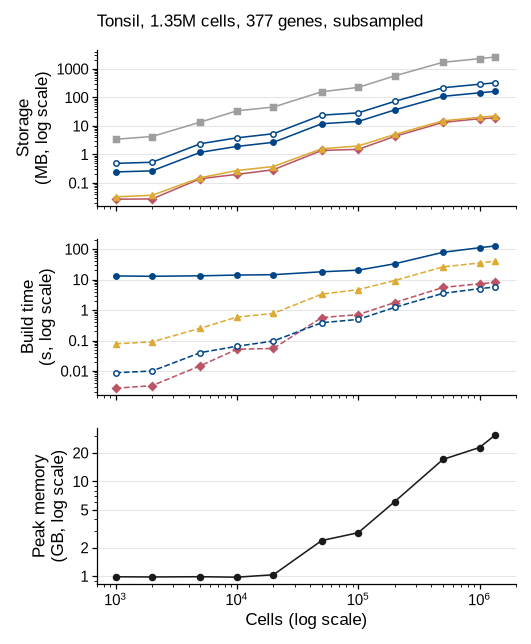

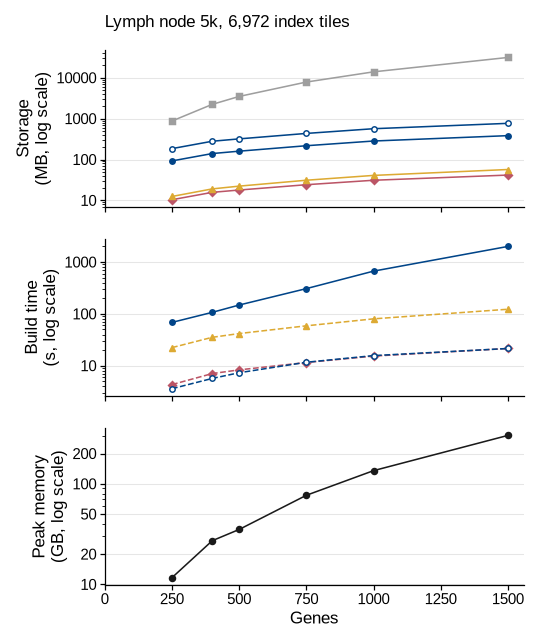

In [4]:
LEFT, RIGHT = 15.0, 2.0


def line(ax, x, y, tier, mk, filled=True, ls="-"):
    k = TC[tier]
    ax.plot(x, y, ls=ls, marker=mk, ms=2.6, color=k, mfc=k if filled else "white", mec=k, mew=0.7, zorder=3)


def panel_ladder(fig, ladder):
    d = lad[lad.ladder == ladder]
    x = d.n_cells if ladder == "cells" else d.p
    if ladder == "cells":
        full = d.iloc[-1]
        title = f"Tonsil, {full.n_cells / 1e6:.2f}M cells, {full.p:.0f} genes, subsampled"
    else:
        title = f"Lymph node 5k, {int(d.n_train.iloc[0]):,} index tiles"
    fig.text(LEFT / W_D, 1 - 0.5 / H2, title, fontsize=ps.LABEL_PT, va="top")
    specs = [("storage", "Storage\n(MB, log scale)", TITLE, H_TOP, 4.0),
             ("time", "Build time\n(s, log scale)", TITLE + H_TOP, H_TOP, 4.0),
             ("memory", "Peak memory\n(GB, log scale)", TITLE + 2 * H_TOP, H_BOTTOM, 10.0)]
    for name, ylabel, y0, h, bottom in specs:
        ax = box(fig, LEFT, y0 + 1.5, W_D - LEFT - RIGHT, h - 1.5 - bottom)
        ax.set_yscale("log")
        ps.plain_log(ax, "y", subs=(1.0,) if name in ("storage", "time") else (1.0, 2.0, 5.0))
        ps.log_grid(ax, "y")
        ax.set_ylabel(ylabel)
        if ladder == "cells":
            ax.set_xscale("log")
            ps.plain_log(ax, "x", subs=(1.0,))
            ax.set_xlim(7e2, 2e6)
            ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _p: f"$10^{{{round(math.log10(v))}}}$"))
        else:
            ax.set_xlim(0, 1560)
            ax.set_xticks(range(0, 1501, 250))
        if name == "memory":
            ax.set_xlabel("Cells (log scale)" if ladder == "cells" else "Genes")
        else:
            ax.set_xticklabels([])
        if name == "storage":
            for c, mk, filled in (("whole", "s", True), ("naive", "o", True), ("spindle", "D", True),
                                  ("naive_partial", "o", False), ("spindle_partial", "^", True)):
                line(ax, x, d[f"bytes_{c}"] / 1e6, "naive" if c == "naive_partial" else c, mk, filled)
        elif name == "time":
            line(ax, x, d.naive_build_s, "naive", "o")
            line(ax, x, d.spindle_s, "spindle", "D", ls="--")
            line(ax, x, d.naive_partial_s, "naive", "o", filled=False, ls="--")
            line(ax, x, d.spindle_partial_s, "spindle_partial", "^", ls="--")
        else:
            ax.plot(x, d.peak_gb_spindle_partial, marker="o", ms=2.6, color=ps.INK, zorder=3)


fig = ps.panel(W_D, H2); panel_ladder(fig, "cells"); ps.save_panel(fig, FIG, "C")
fig = ps.panel(W_D, H2); panel_ladder(fig, "genes"); ps.save_panel(fig, FIG, "D")

## Legend (shared by B–D)

In [5]:
def panel_legend(fig):
    def h(tier, mk, label, filled=True):
        k = TC[tier]
        return Line2D([], [], ls="", marker=mk, ms=3.5, color=k, mfc=k if filled else "white", mec=k, mew=0.8,
                      label=label)

    handles = [h("whole", "s", "Whole covariances"), h("naive", "o", "Spindle-naive"), h("spindle", "D", "Spindle (whole tiles)"),
               h("naive", "o", "Spindle-naive (gene sets)", filled=False),
               h("spindle_partial", "^", "Spindle (gene sets)")]
    fig.legend(handles=handles, ncol=5, loc="center")


fig = ps.panel(178, 5); panel_legend(fig); ps.save_panel(fig, FIG, "legend")

figures/figS1_build/panels/legend.pdf/.png: 178 x 5 mm, 0.0 / 0.1 MB


<Figure size 1051.18x29.5276 with 0 Axes>

## Full figure

figures/figS1_build/figS1_build.pdf/.png: 180 x 178 mm, 0.0 / 2.3 MB


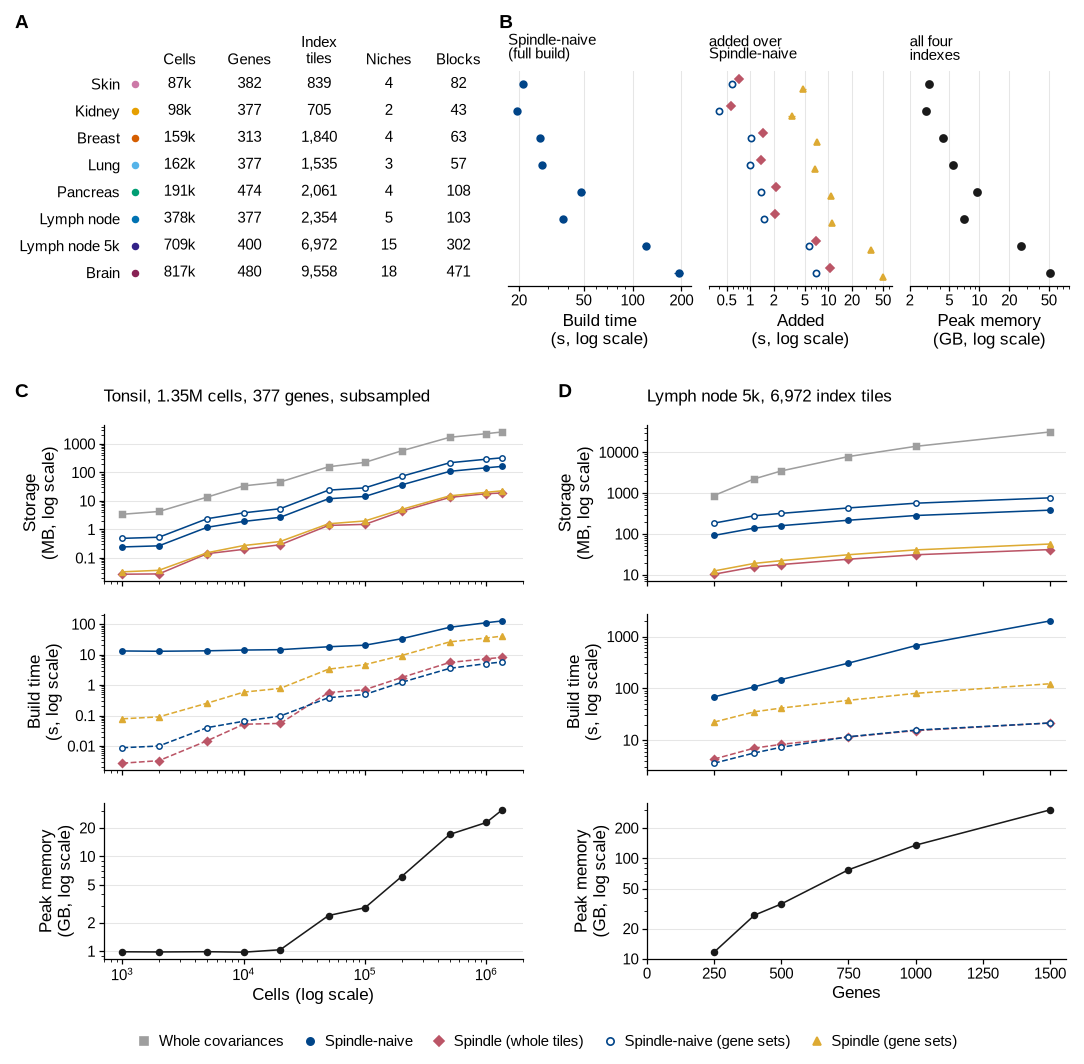

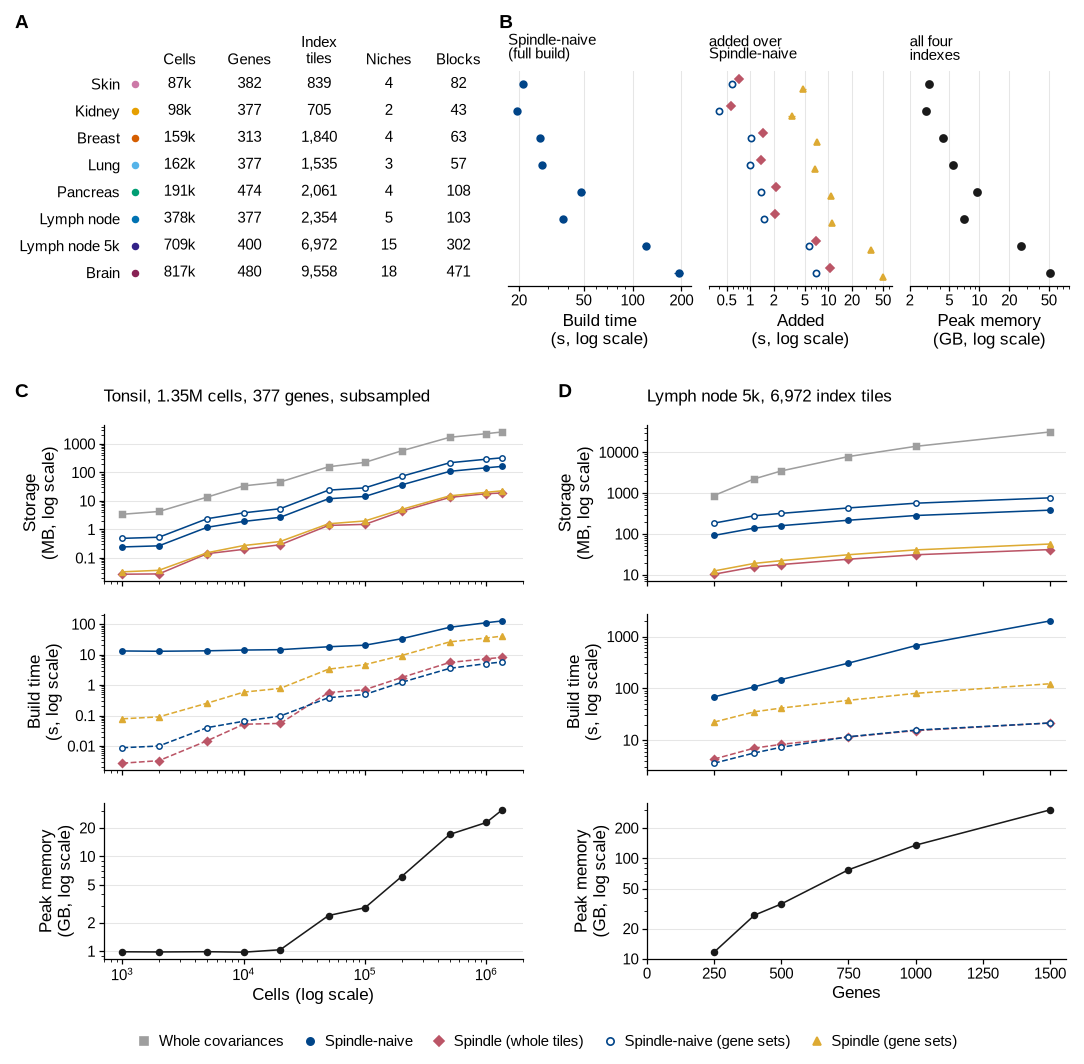

In [6]:
Y1, Y2 = 3.0, 3.0 + H1 + 6.0
Y_LEG = Y2 + H2 + 1.5
page = ps.page(180, Y_LEG + 6.0)
panel_a(ps.place(page, "A", 0, Y1, W_A, H1, dy=-3.0))
panel_c(ps.place(page, "B", W_A, Y1, W_C, H1, dy=-3.0))
panel_ladder(ps.place(page, "C", 0, Y2, W_D, H2, dy=-0.5), "cells")
panel_ladder(ps.place(page, "D", 92, Y2, W_D, H2, dy=-0.5), "genes")
panel_legend(ps.place(page, None, 1, Y_LEG, 178, 5))
ps.save_figure(page, FIG)
page